# Needle — Clustering and Hidden Markov Models

**Review 2 · 20 marks**

**Problem:** find the seconds in a video that answer a natural-language query.
We extend the existing picture-and-speech search project with clustering and
a temporal probabilistic model. The original regression/classification work
remains in `analysis.ipynb`; this notebook covers the new review.

| Professor's criterion | Evidence here | Marks |
|---|---|---|
| Problem identification & dataset selection | Section 1 | 4 |
| Implementation of clustering | Section 2 | 4 |
| Implementation of Hidden Markov Model | Section 3 | 4 |
| Comparative performance analysis | Section 4 | 4 |
| Result interpretation & presentation | Section 5 | 4 |

**Run all cells.** Cached matching experiments are reused; missing/stale folds
are fitted again. No video download or encoder inference is needed when the
existing feature table is available. Use Python 3.10+ and install
`requirements-review.txt`; a Jupyter UI may be installed separately if desired.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'config.yaml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.yaml').exists(), 'Run from the project root or notebooks directory.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.runtime' / 'matplotlib'))

import json
import inspect
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from cmvs.config import load_config
from analysis.review import run_review, ordered_sequences
from analysis.hmm import GaussianHMM, forward_backward

cfg = load_config()
run_review(cfg)
OUT = cfg.review.output_dir
dataset = pd.read_csv(cfg.ml.tables_dir / 'dataset.csv.gz')
predictions = pd.read_csv(OUT / 'predictions.csv.gz')
comparison = pd.read_csv(OUT / 'comparison.csv')
details = json.loads((OUT / 'model_details.json').read_text())
manifest = json.loads((OUT / 'manifest.json').read_text())
print('Artifact signature:', manifest['signature'])

Reuse a-remote-possibility
Reuse administrator-chats-astronauts
Reuse commercial-crew-milestone
Reuse cosmic-phenomenon
Reuse hubble-exoplanet
Reuse mars-mission-briefed
Reuse new-explorers-new-roadmap
Reuse smoke-and-fire
Reuse this-week-at-nasa
                      method       f1   pr_auc  hit_at_1      mrr  temporal_iou
                     K-means 0.633086 0.696256  0.930247 0.941637      0.490947
            Gaussian mixture 0.557284 0.556275  0.768519 0.853072      0.419360
                Gaussian HMM 0.553742 0.472922  0.571296 0.733013      0.415401
         Fixed-weight fusion 0.500120 0.603975  0.881173 0.920376      0.365074
                Picture only 0.331906 0.368250  0.612654 0.721457      0.218498
                 Speech only 0.528504 0.598814  0.902469 0.918540      0.407644
         Logistic regression 0.761000 0.845327  0.944136 0.948135      0.625845
        k-nearest neighbours 0.743191 0.812284  0.917901 0.938088      0.612258
Gradient boosting classifier 0.74

## 1. Problem identification & dataset selection — 4 marks

A long video can contain several unrelated topics. Picture similarity can
retrieve a visually matching scene, while speech similarity can find a
concept that is only mentioned. The practical task is to return the relevant
time interval, rather than asking the user to watch the whole video.

**Question:** can clustering group seconds into useful relevance patterns,
and can temporal transitions improve predictions compared with independent
clustering and the previous supervised models?

### Training datasets and model provenance

The model-training datasets are documented below. They have different roles from
the videos a user uploads to the web application for searching.

#### Datasets used to train the pretrained encoders

These encoders were trained by their original authors. This project loads their
released weights and keeps them frozen; we did not retrain them on these corpora.

| Model used in this project | Original training dataset / corpus | Purpose in our pipeline |
|---|---|---|
| OpenCLIP ViT-B/32, `laion2b_s34b_b79k` | **LAION-2B English**, the approximately two-billion image–text-pair English subset of LAION-5B. | Provides aligned visual and text embeddings for matching queries to frames. |
| Whisper `base`, through faster-whisper | **OpenAI's 680,000-hour multilingual audio–transcript corpus**, collected from the internet. The faster-whisper checkpoint is a CTranslate2 conversion of the released Whisper base model. | Converts speech into timestamped text. |
| Sentence Transformer `all-MiniLM-L6-v2` | **A mixed sentence-pair training collection with over one billion pairs/tuples**. Sources include Reddit comments, S2ORC, WikiAnswers, PAQ, Stack Exchange, MS MARCO, and other datasets listed in the model card. This sentence-embedding training builds on a pretrained MiniLM backbone. | Encodes queries and transcript segments for semantic similarity. |

Sources: [OpenCLIP model card](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K),
[Whisper training-data description](https://github.com/openai/whisper/blob/main/model-card.md#training-data),
[faster-whisper base conversion](https://huggingface.co/Systran/faster-whisper-base),
[MiniLM sentence-embedding training data](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2#training-data).

#### Dataset used to train or fit models in this project

Our own fitted models use the **labeled query–second relevance feature dataset**
stored in `results/ml/dataset.csv.gz`. Its annotations are in
`benchmark/queries.json`; `analysis/features.py` constructs the feature table.

| Models fitted by us | Training input | Training target / objective |
|---|---|---|
| Ridge, Random Forest, Gradient Boosting regressors | 31 engineered relevance features per query–second row. | Predict graded relevance (`rel_graded`). |
| Logistic Regression, k-nearest neighbours, Gradient Boosting classifiers | The same 31-feature dataset. | Predict whether the second belongs to the answer interval (`rel_binary`). |
| K-means and Gaussian mixture model | Eight selected features from the same dataset, standardized on the training fold. | Discover clusters without labels. Training labels subsequently calibrate cluster relevance. |
| Gaussian Hidden Markov Model | The same eight-feature subset, ordered into separate query–video sequences. | Learn Gaussian emissions and state transitions without labels. Training labels subsequently calibrate state relevance. |

**Dataset size and origin:** 28,900 labeled query–second rows, 86 annotated queries,
and nine source recordings from NASA news. There are 2,385 relevant rows (8.3%).
The source recordings are the material from which this training benchmark was
constructed. Their role here is established by the saved feature table and
annotations, rather than by which videos happen to appear in the web app.

**Training/evaluation split:** leave one entire source video out per fold. Each
model is fitted on rows from eight source videos and evaluated on the remaining
video, for nine folds. Preprocessing, model selection and relevance calibration
use the training fold only. The 28,900 rows describe the complete benchmark;
they are not all used for training in any one fold.

**Why this dataset:** the rows directly represent the relevance prediction task,
and their temporal order supports the HMM. The benchmark provides both graded
and binary labels, allowing the existing and new models to be compared. Labels
were derived from transcripts, so the benchmark favors speech and has limited
domain diversity.

**Web-app uploads:** ingestion extracts frames, transcripts and embeddings and
builds search indexes. Uploading a video does not fit these analysis models or
update the pretrained encoder weights. A source recording may also be available
as a demo, but that does not define the training dataset.

MSR-VTT and Charades appear in evaluation-harness code, but the saved experiments
have not been trained or evaluated on those datasets.

,measure,value
0,Videos,9.000000
1,Queries,86.000000
2,Query-second rows,28900.000000
3,Relevant rows,2385.000000
4,Relevant fraction,0.082526


,video_id,query_id,t,visual_norm,speech_norm,visual_vs_peak,speech_vs_peak,keyword_overlap,fused_peak_dist,frame_change,in_speech,rel_binary
0,a-remote-possibility,0,0.0,0.044807,0.0,0.081452,0.0,0.0,18.0,0.000000,0,0
1,a-remote-possibility,0,1.0,0.101778,0.0,0.185632,0.0,0.0,17.0,0.233682,0,0
2,a-remote-possibility,0,2.0,0.134512,0.0,0.223090,0.0,0.0,16.0,0.297151,0,0
3,a-remote-possibility,0,3.0,0.518953,0.0,0.249762,0.0,0.0,15.0,0.421712,0,0
4,a-remote-possibility,0,4.0,0.215287,0.0,0.286514,0.0,0.0,14.0,0.320462,0,0


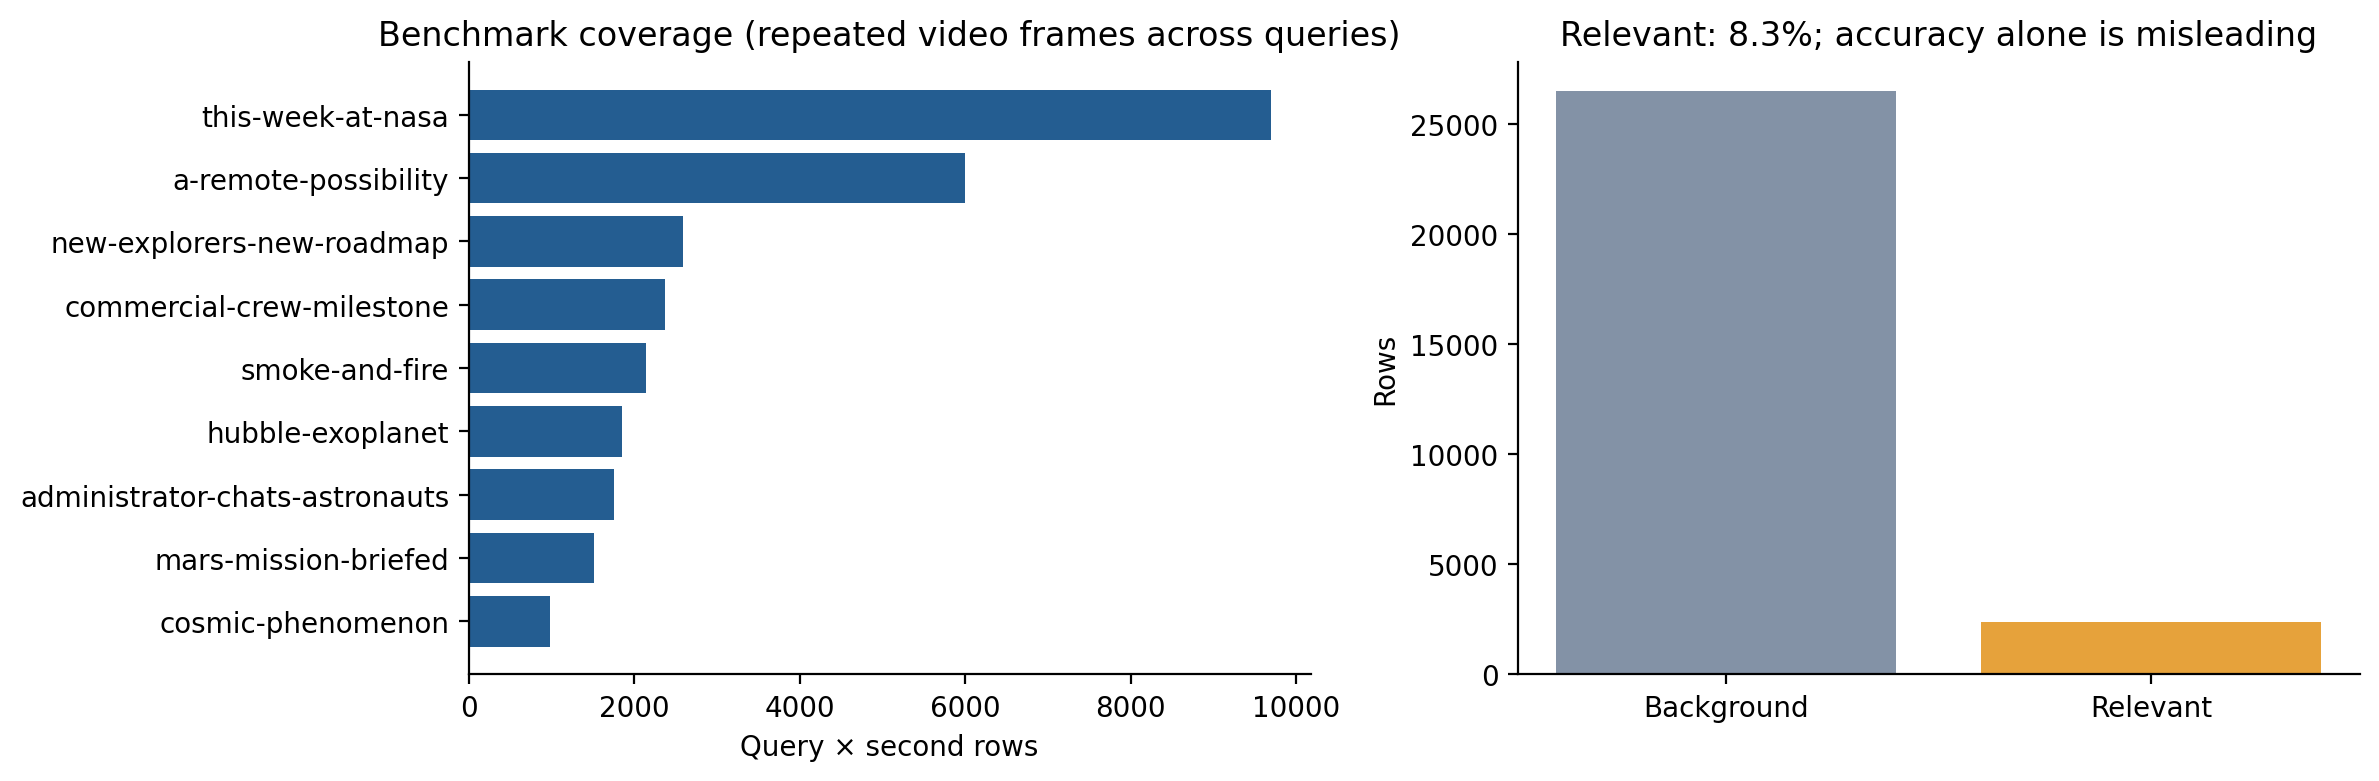

In [2]:
display(pd.DataFrame({
    'measure': ['Videos', 'Queries', 'Query-second rows', 'Relevant rows', 'Relevant fraction'],
    'value': [dataset.video_id.nunique(), dataset.query_id.nunique(), len(dataset),
              int(dataset.rel_binary.sum()), float(dataset.rel_binary.mean())]
}))
display(dataset[['video_id', 'query_id', 't', *cfg.review.features, 'rel_binary']].head())
display(Image(filename=str(OUT / 'figures' / '01_dataset.png')))

### Preprocessing and leakage prevention

We select eight configured picture, speech, keyword, peak-distance,
scene-change and speech-presence features. These include whole-video context,
so the intended application is **offline search**, not causal streaming.

Leave-one-video-out evaluation holds out all queries from one video together.
StandardScaler is fitted on the remaining videos only. Cluster/state counts,
relevance mappings and thresholds also use training videos only. Each
`(video_id, query_id)` is sorted by time and passed as its own HMM sequence.
The HMM never transitions from one query/video to another.

In [3]:
fold = details[0]
train, train_lengths = ordered_sequences(dataset[dataset.video_id != fold['held_out']])
test, test_lengths = ordered_sequences(dataset[dataset.video_id == fold['held_out']])
assert fold['held_out'] not in fold['training_videos']
assert sum(train_lengths) == len(train) and sum(test_lengths) == len(test)
display(pd.DataFrame({'feature': fold['features'], 'training_mean': fold['scaler_mean'],
                      'training_scale': fold['scaler_scale']}))
print('Held out:', fold['held_out'])
print('Training videos:', fold['training_videos'])
print('Training/test sequences:', len(train_lengths), len(test_lengths))

Held out: a-remote-possibility
Training videos: ['administrator-chats-astronauts', 'commercial-crew-milestone', 'cosmic-phenomenon', 'hubble-exoplanet', 'mars-mission-briefed', 'new-explorers-new-roadmap', 'smoke-and-fire', 'this-week-at-nasa']
Training/test sequences: 71 15


,feature,training_mean,training_scale
0,visual_norm,0.440061,0.199158
1,speech_norm,0.268667,0.226098
2,visual_vs_peak,0.485512,0.186156
3,speech_vs_peak,0.277620,0.209722
4,keyword_overlap,0.032300,0.102952
5,fused_peak_dist,138.152489,130.626606
6,frame_change,0.211720,0.217273
7,in_speech,0.974061,0.158953


## 2. Implementation of clustering — 4 marks

**K-means** alternates assigning each point to its nearest centroid and
updating centroids to minimize within-cluster squared Euclidean distance:

$$J = \sum_i \|x_i - \mu_{c_i}\|^2.$$

Candidate cluster counts are 2, 3, 4 and 5. The highest **training silhouette**
score chooses the count; silhouette compares within-cluster distance with
distance to the nearest other cluster. A fixed seeded training sample keeps
the computation small. PCA is a 2D illustration fitted on training data,
not an input to clustering or a basis for choosing the model.

**Gaussian mixture model (GMM)** is the second clustering method. It models
a mixture of diagonal Gaussian components and assigns soft memberships.
Training BIC chooses its component count. Clustering labels are arbitrary;
a cluster ID is not automatically “relevant.”

To compare retrieval performance, we estimate each cluster's relevant
fraction using **training labels only**. GMM posteriors weight these fractions.
K-means interpolates them using softmax of negative mean squared centroid
distances. Thus, fitting and model selection are unsupervised; the complete
relevance scorer includes supervised calibration.

,held_out,method,k,silhouette,inertia,bic,converged,iterations
0,a-remote-possibility,K-means,2,0.330295,139089.076211,NaN,NaN,NaN
1,a-remote-possibility,K-means,3,0.198333,118708.703774,NaN,NaN,NaN
2,a-remote-possibility,K-means,4,0.224846,95928.177719,NaN,NaN,NaN
3,a-remote-possibility,K-means,5,0.239989,83053.959069,NaN,NaN,NaN
4,a-remote-possibility,Gaussian mixture,2,0.278258,NaN,411605.252165,True,NaN
5,a-remote-possibility,Gaussian mixture,3,0.354058,NaN,338536.883654,True,NaN
6,a-remote-possibility,Gaussian mixture,4,0.202634,NaN,324335.151288,True,NaN
7,a-remote-possibility,Gaussian mixture,5,0.173948,NaN,314993.140442,False,NaN
10,administrator-chats-astronauts,K-means,2,0.326366,167447.254455,NaN,NaN,NaN
11,administrator-chats-astronauts,K-means,3,0.367559,139357.840766,NaN,NaN,NaN


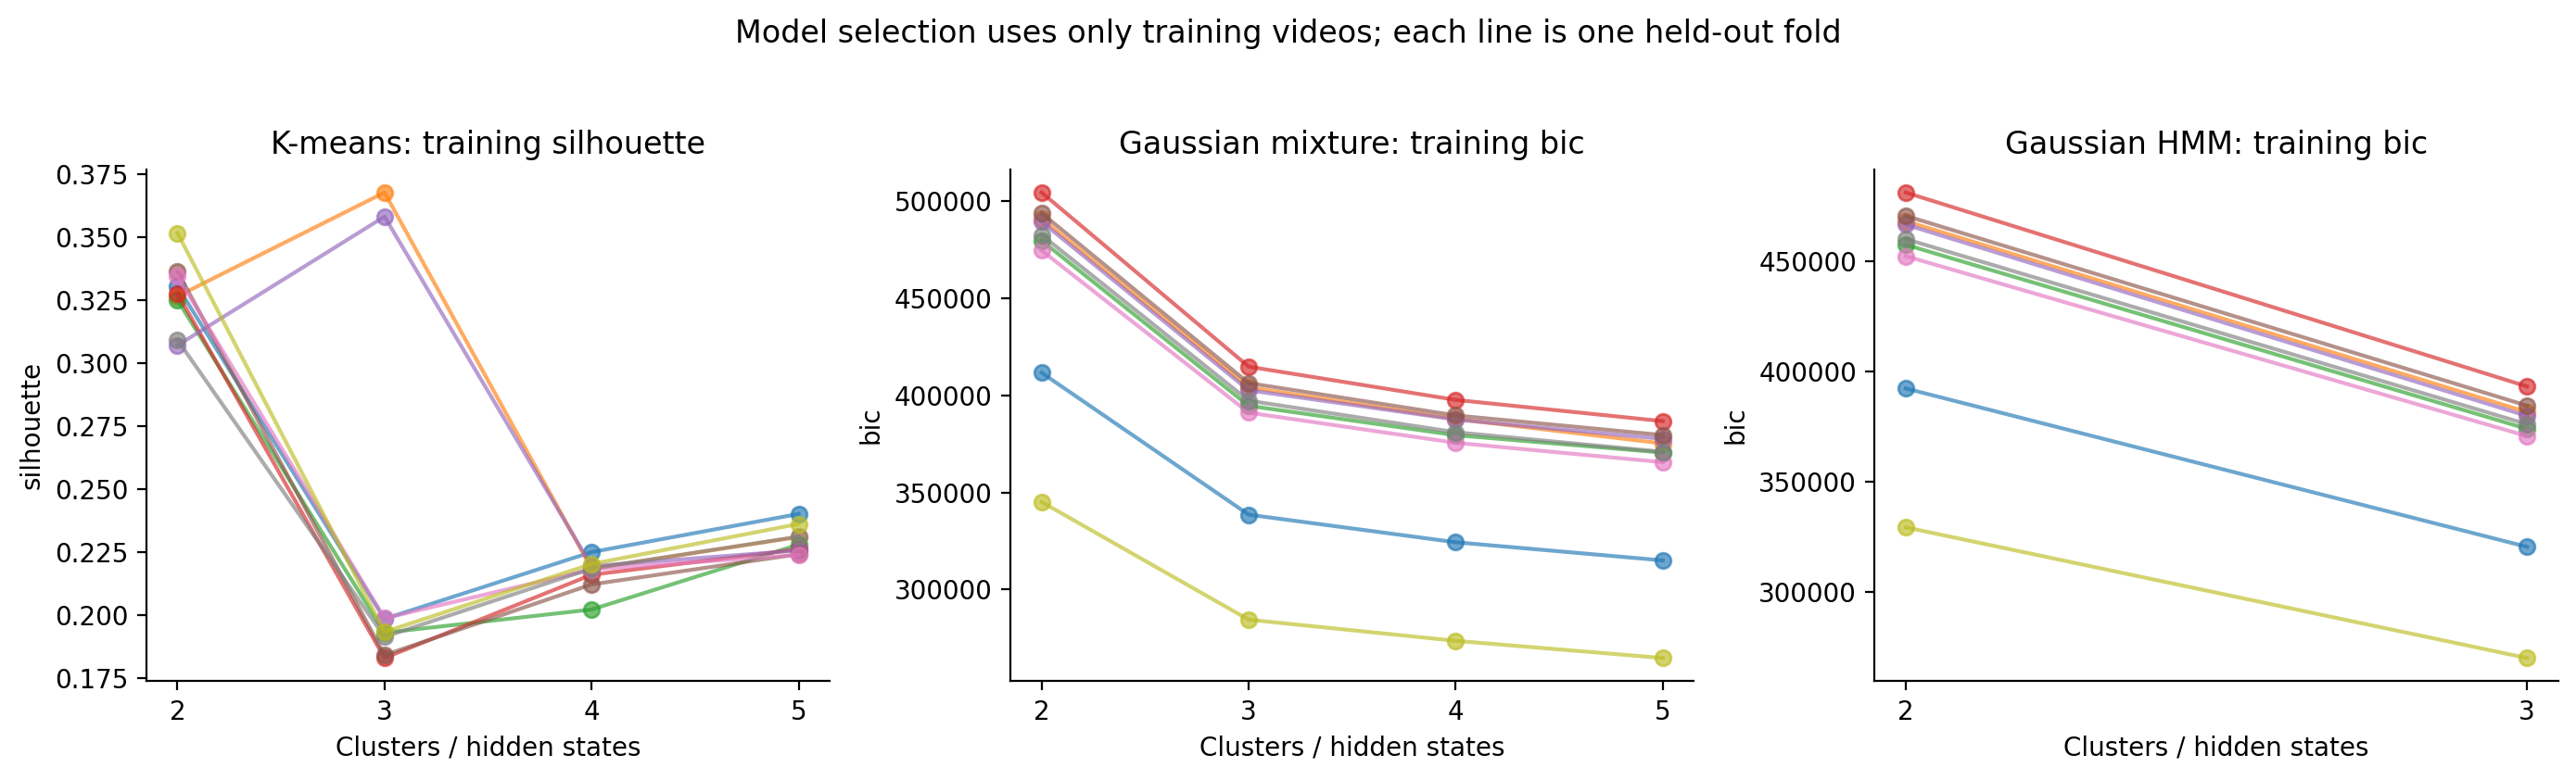

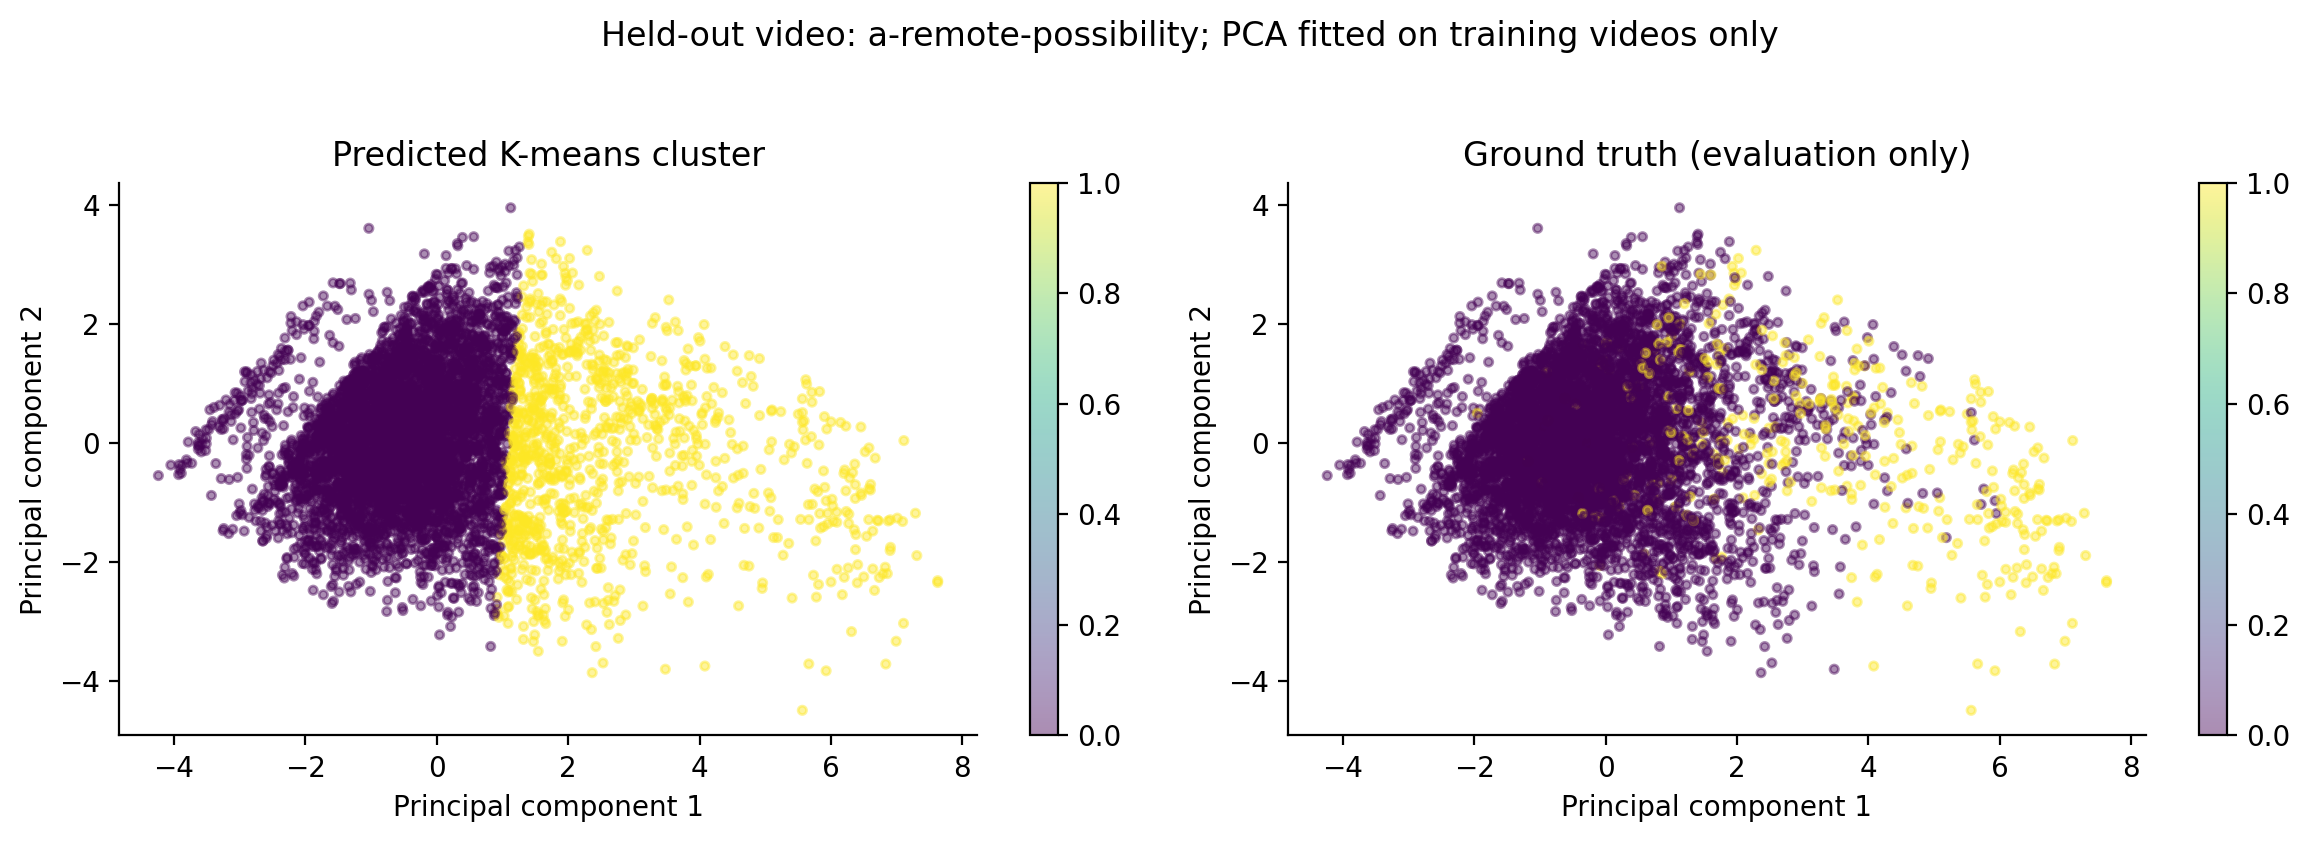

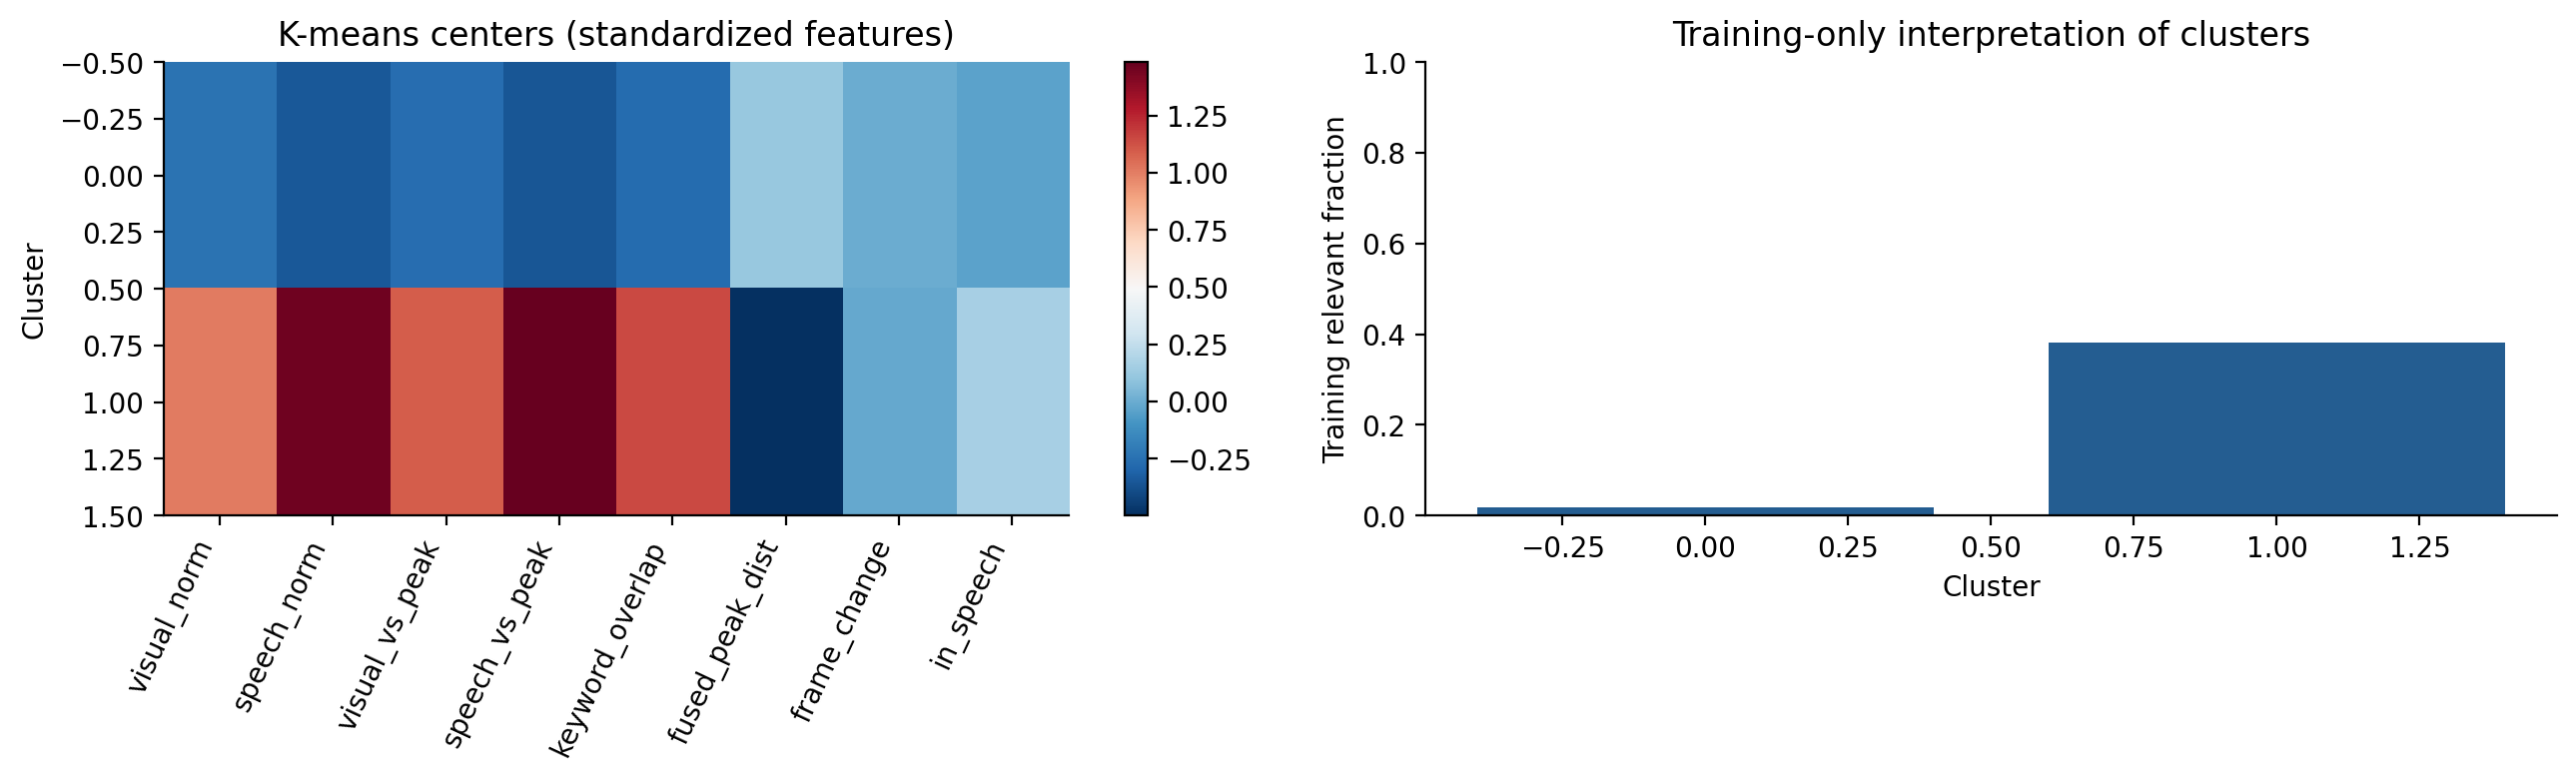

In [4]:
selection = pd.read_csv(OUT / 'model_selection.csv')
display(selection[selection.method.isin(['K-means', 'Gaussian mixture'])].head(12))
display(Image(filename=str(OUT / 'figures' / '02_model_selection.png')))
display(Image(filename=str(OUT / 'figures' / '03_cluster_projection.png')))
display(Image(filename=str(OUT / 'figures' / '04_cluster_interpretation.png')))

## 3. Implementation of Hidden Markov Model — 4 marks

Observations $x_t$ are the standardized feature vectors at successive seconds.
Hidden state $z_t$ describes an unobserved feature pattern. State IDs have no
semantic labels during fitting. A Gaussian HMM estimates:

- Initial distribution $\pi_j=P(z_1=j)$.
- Transition probabilities $A_{ij}=P(z_t=j\mid z_{t-1}=i)$.
- Emission density $b_j(x_t)=\mathcal N(x_t;\mu_j,\mathrm{diag}(\sigma_j^2))$.

The Markov assumption uses the preceding state; the diagonal covariance
approximation assumes conditionally independent feature dimensions. These
simplify the model but may not fit correlated video-search features well.

**Forward:** $\alpha_t(j)=b_j(x_t)\sum_i\alpha_{t-1}(i)A_{ij}$.
**Backward:** $\beta_t(i)=\sum_j A_{ij}b_j(x_{t+1})\beta_{t+1}(j)$.
Their scaled product gives posterior state probabilities. The implementation
shifts emissions and rescales each timestamp to prevent underflow.

**Baum–Welch:** use posteriors to estimate expected state/transition counts,
then update initial probabilities, transitions, means and variances. K-means
supplies initialization. Positive transition pseudocounts and a variance
floor prevent degenerate estimates. Two and three states are considered;
training BIC selects the state count.

**Viterbi:** replace the forward sum by a maximum in log space, record
backpointers, then trace back the most probable joint state sequence.

`analysis/hmm.py` implements these steps directly. Training-label state
calibration converts smoothed posteriors to relevance scores. Thresholding
that score is different from interpreting the Viterbi state IDs as labels.

In [5]:
# The actual forward-backward implementation used in every experiment.
print(inspect.getsource(forward_backward))

def forward_backward(
    log_emission: np.ndarray, start: np.ndarray, transition: np.ndarray
) -> tuple[float, np.ndarray, np.ndarray]:
    """Return sequence log likelihood, state posteriors, and expected transitions.

    Emissions are shifted per timestamp and forward probabilities are scaled each
    step. The backward recursion uses the same scales to avoid underflow.
    """
    shifts = log_emission.max(axis=1)
    emission = np.exp(log_emission - shifts[:, None])
    n, k = emission.shape
    alpha, beta = np.empty((n, k)), np.ones((n, k))
    scales = np.empty(n)
    alpha[0] = start * emission[0]
    scales[0] = alpha[0].sum()
    alpha[0] /= scales[0]
    for t in range(1, n):
        alpha[t] = (alpha[t - 1] @ transition) * emission[t]
        scales[t] = alpha[t].sum()
        alpha[t] /= scales[t]
    for t in range(n - 2, -1, -1):
        beta[t] = transition @ (emission[t + 1] * beta[t + 1]) / scales[t + 1]
    gamma = alpha * beta
    gamma /= gamma.sum(axis=1, keepdi

,t,Viterbi state,relevance score
0,0.0,0,0.005691
1,1.0,0,0.005691
2,2.0,0,0.005691
3,3.0,0,0.005691
4,4.0,0,0.005691
5,5.0,0,0.005691
6,6.0,0,0.005691
7,7.0,2,0.356916
8,8.0,2,0.356916
9,9.0,2,0.356916


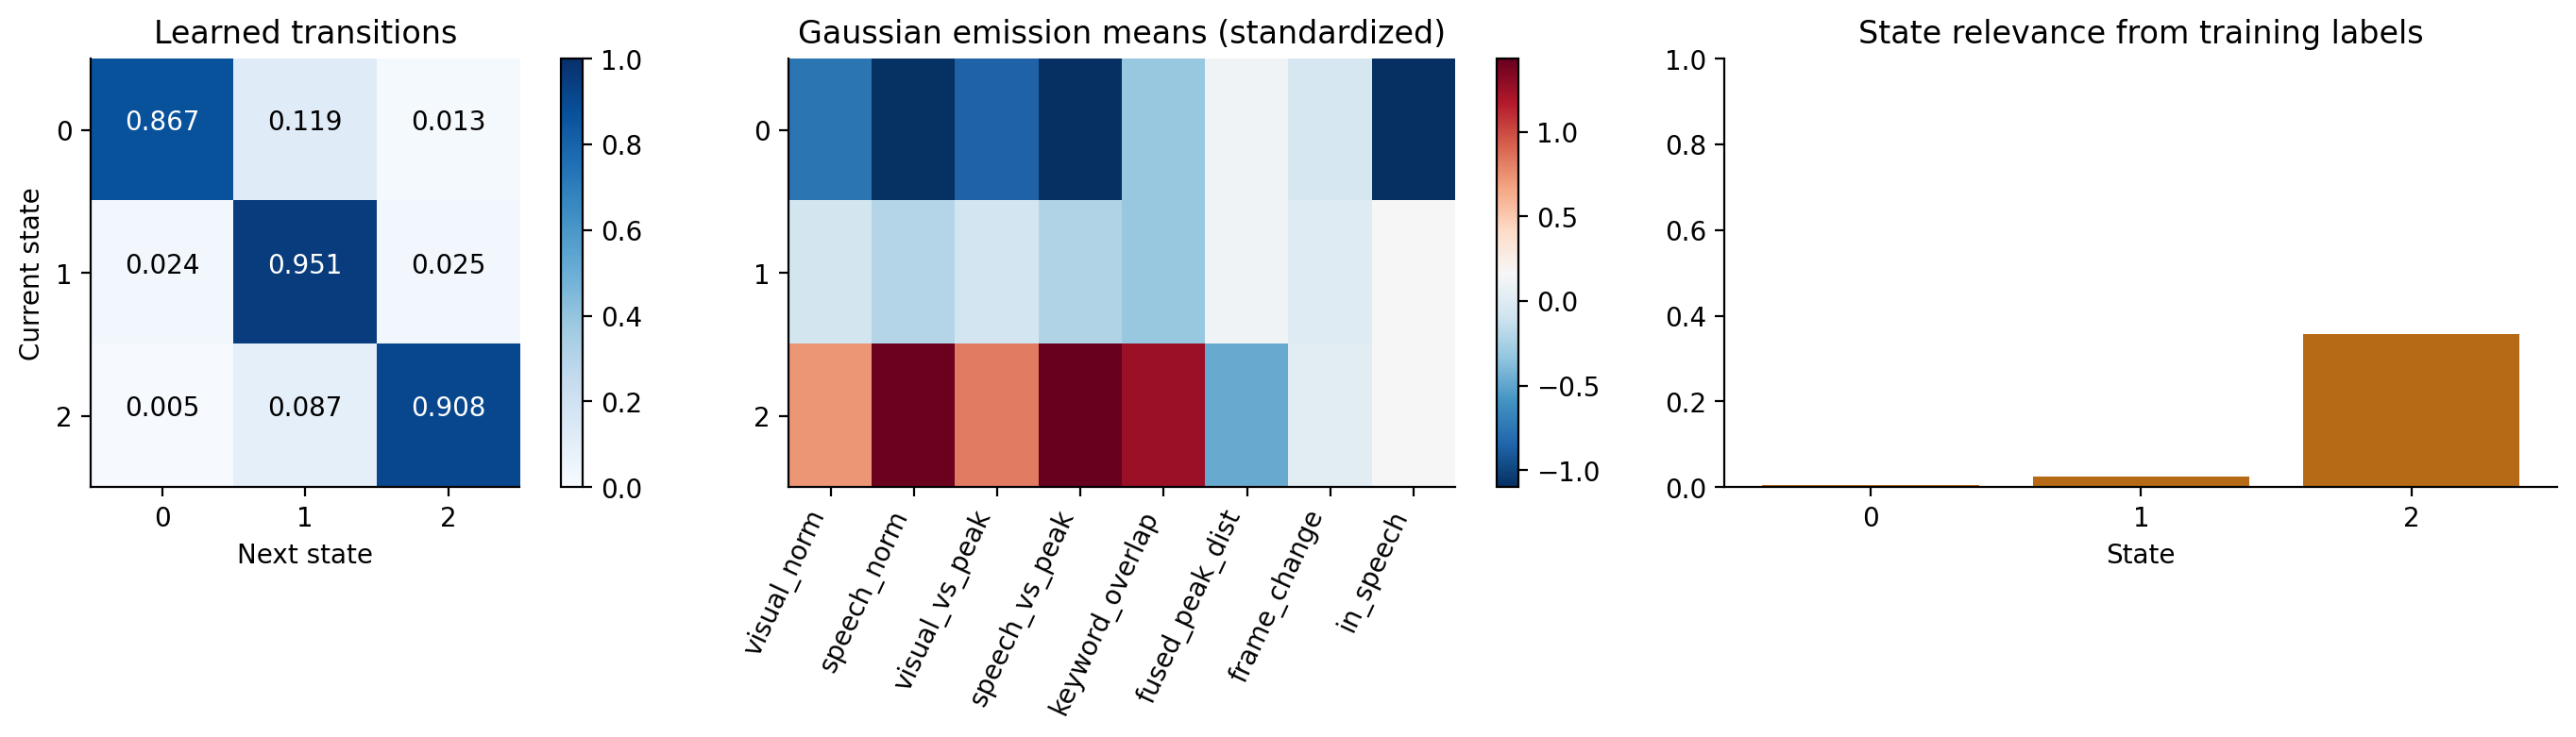

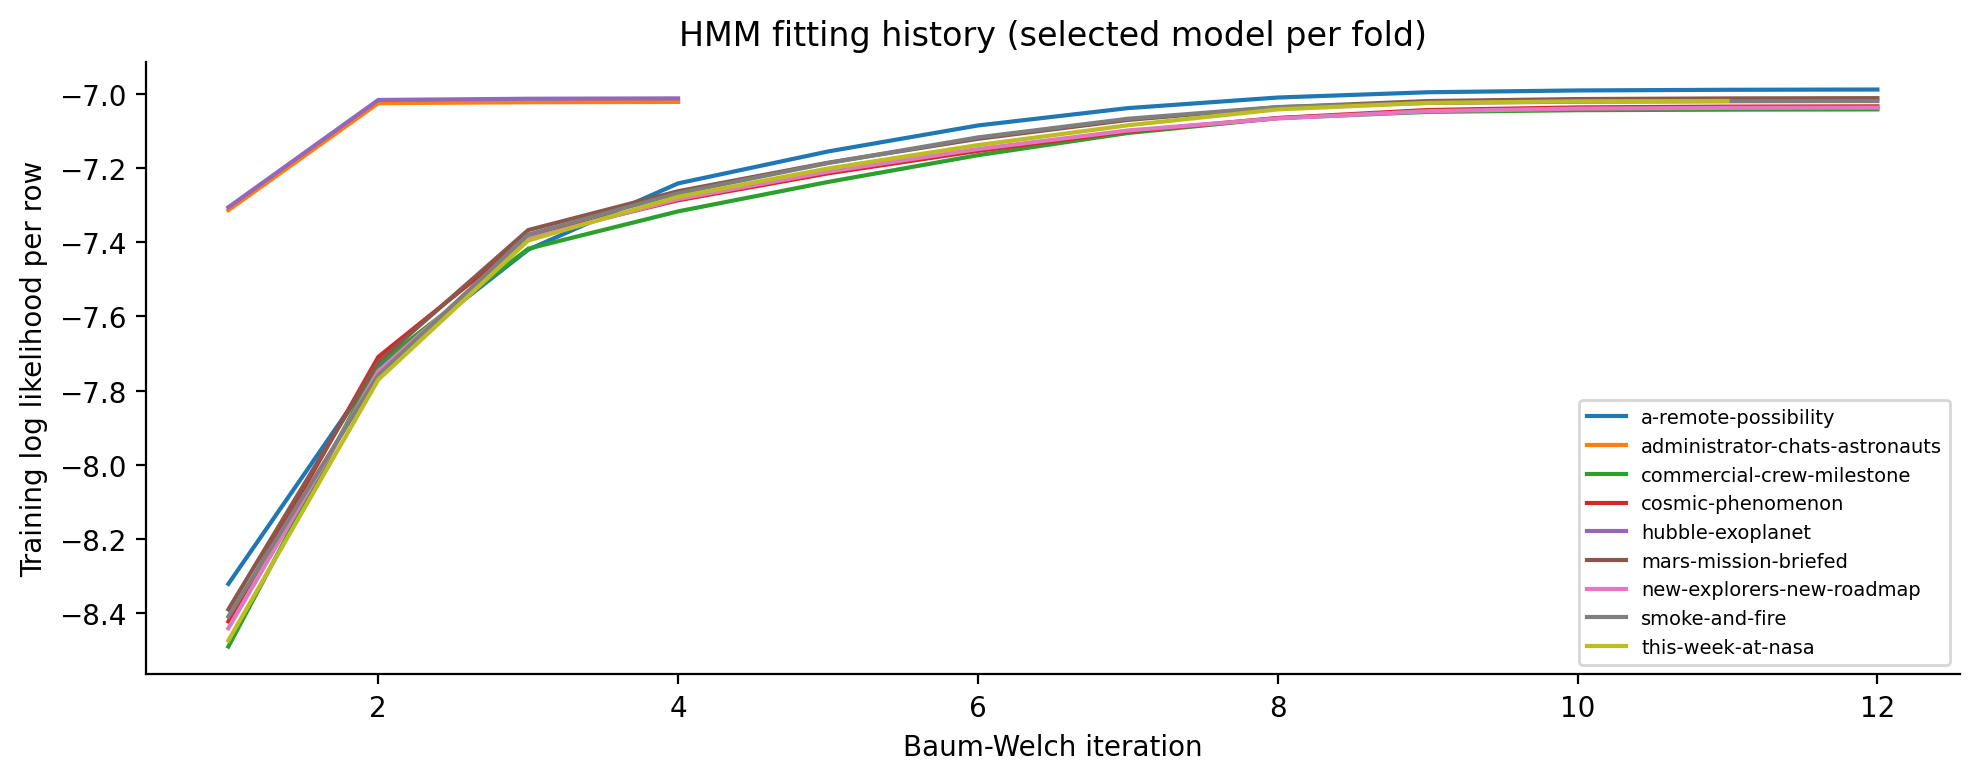

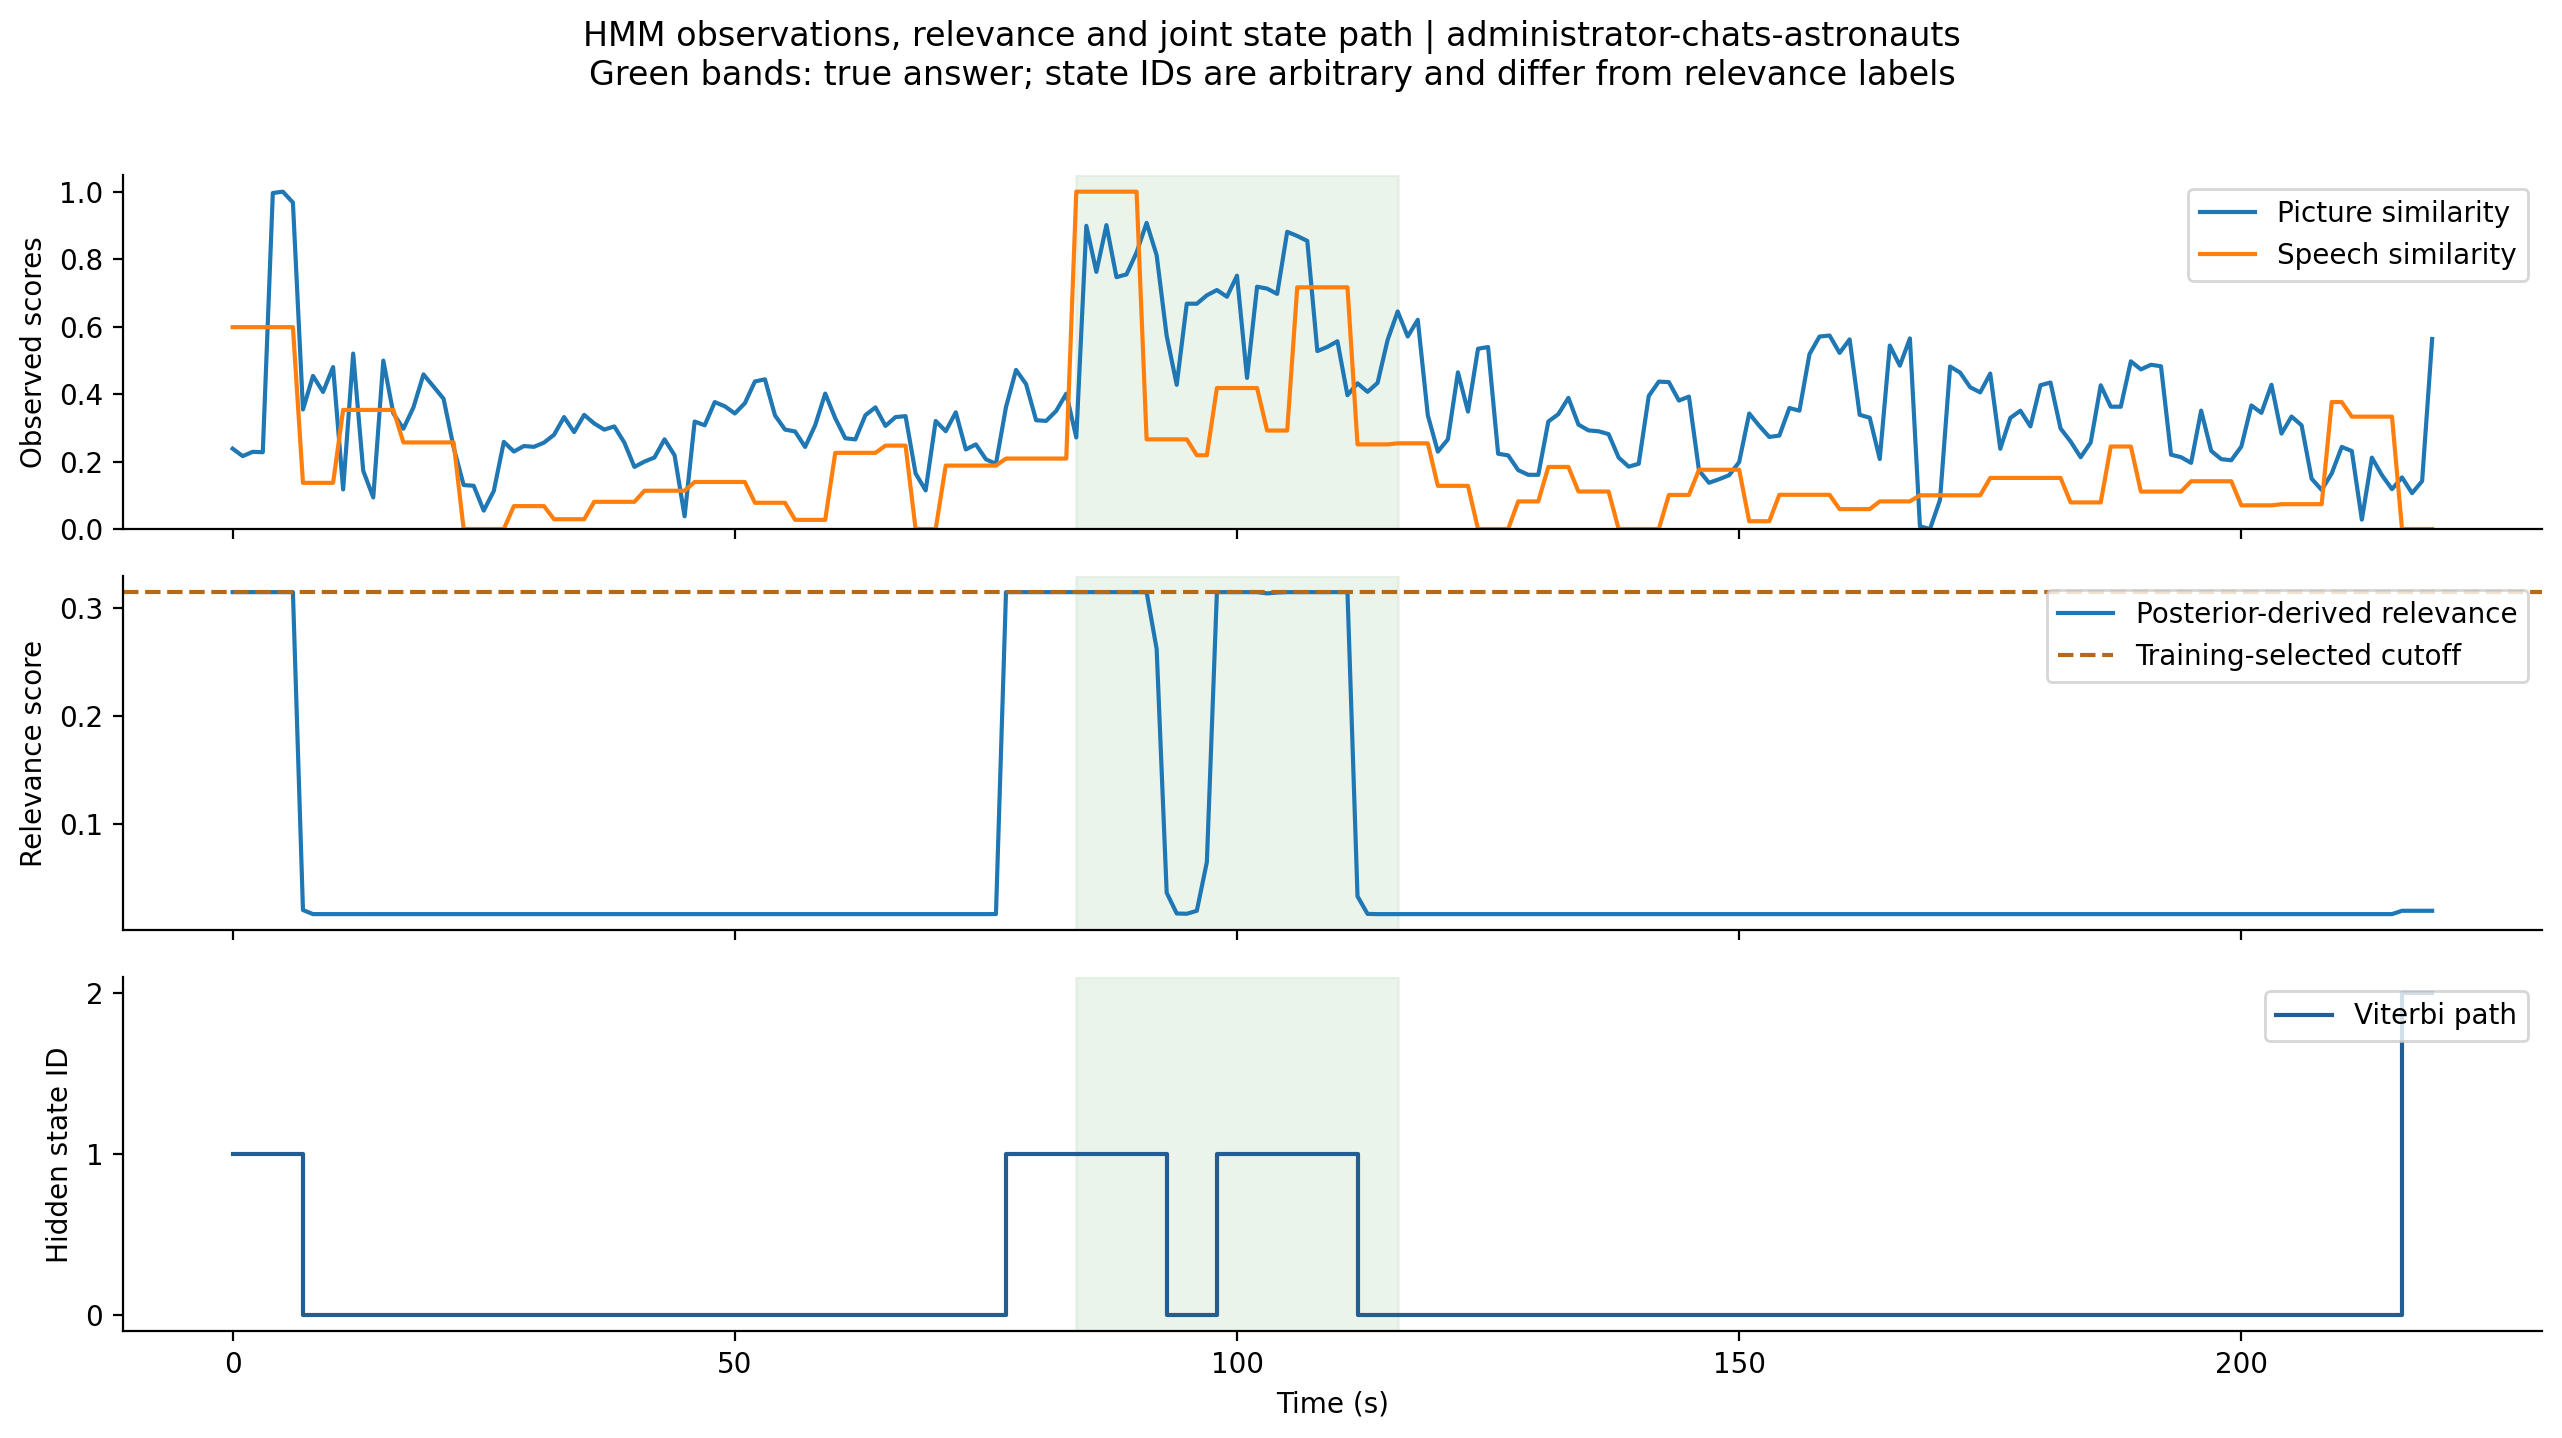

In [6]:
# Reconstruct one fitted fold model from its saved numerical parameters.
parameters = fold['models']['Gaussian HMM']
model = GaussianHMM(parameters['k'], max_iter=cfg.review.max_iter,
                    tol=cfg.review.tolerance, min_covar=cfg.review.min_covar,
                    pseudocount=cfg.review.pseudocount, n_init=cfg.review.n_init,
                    random_state=cfg.ml.seed)
model.startprob_ = np.array(parameters['startprob'])
model.transmat_ = np.array(parameters['transmat'])
model.means_ = np.array(parameters['means'])
model.covars_ = np.array(parameters['covars'])
model.n_features_in_ = len(fold['features'])
X_test = (test[fold['features']].to_numpy() - fold['scaler_mean']) / fold['scaler_scale']
posterior = model.predict_proba(X_test, test_lengths)
viterbi = model.predict(X_test, test_lengths)
np.testing.assert_allclose(posterior.sum(axis=1), 1.0)
saved = predictions[predictions.video_id == fold['held_out']].sort_values(['video_id', 'query_id', 't'])
np.testing.assert_allclose(posterior @ parameters['state_relevance'], saved['Gaussian HMM'])
np.testing.assert_array_equal(viterbi, saved['Gaussian HMM__state'])
display(pd.DataFrame({'t': test.t.head(12), 'Viterbi state': viterbi[:12],
                      'relevance score': (posterior @ parameters['state_relevance'])[:12]}))
display(Image(filename=str(OUT / 'figures' / '05_hmm_parameters.png')))
display(Image(filename=str(OUT / 'figures' / '06_hmm_convergence.png')))
display(Image(filename=str(OUT / 'figures' / '09_viterbi_decoding.png')))

## 4. Comparative performance analysis — 4 marks

All methods are evaluated on the same held-out seconds. New K-means, GMM and
HMM predictions are compared with picture-only, speech-only, fixed fusion,
and the three earlier classifiers. Previous saved predictions are joined by
unique `(video, query, time)` keys and their labels are verified before reuse.

- **Precision/recall/F1:** per-second relevance decisions.
- **PR-AUC:** average precision; useful for the 8.3% positive class.
- **Hit@1/5:** a relevant second appears among the top 1/5 ranked seconds.
- **MRR:** reciprocal rank of the first relevant second.
- **Temporal IoU:** intersection/union of all predicted relevant seconds and
  true relevant seconds for a query; this is not top-clip IoU.

Report **macro averages over videos**, with within-video means over queries
for retrieval/IoU. These differ from the earlier report's query-pooled retrieval
numbers. Intervals bootstrap whole videos; only nine independent video groups
are available. Accuracy alone is misleading given the large background class.

**Calibration caveat:** new score-to-relevance mappings and F1 thresholds
are chosen on training rows in-sample. The earlier classifiers used grouped
inner cross-validation. Fixed baselines retain their configured cutoff. All
avoid held-out labels, but these differing calibration protocols limit direct
attribution of differences to model architecture alone.
Ranking and threshold-free metrics round scores to the configured 12 decimal
places. Ranking then uses shared seeded tie-breaking, so CSV round-trip noise
cannot break posterior plateaus.

,method,precision,recall,f1,pr_auc,hit_at_1,hit_at_5,mrr,temporal_iou
0,K-means,0.646,0.633,0.633,0.696,0.930,0.965,0.942,0.491
1,Gaussian mixture,0.630,0.521,0.557,0.556,0.769,0.971,0.853,0.419
2,Gaussian HMM,0.575,0.557,0.554,0.473,0.571,0.956,0.733,0.415
3,Fixed-weight fusion,0.381,0.763,0.500,0.604,0.881,0.966,0.920,0.365
4,Picture only,0.216,0.778,0.332,0.368,0.613,0.861,0.721,0.218
5,Speech only,0.469,0.638,0.529,0.599,0.902,0.924,0.919,0.408
6,Logistic regression,0.728,0.811,0.761,0.845,0.944,0.952,0.948,0.626
7,k-nearest neighbours,0.688,0.820,0.743,0.812,0.918,0.952,0.938,0.612
8,Gradient boosting classifier,0.709,0.805,0.747,0.832,0.930,0.952,0.937,0.609


,method,f1_lo,f1_hi,hit_at_1_lo,hit_at_1_hi
0,K-means,0.583,0.679,0.856,1.000
1,Gaussian mixture,0.517,0.593,0.693,0.852
2,Gaussian HMM,0.500,0.602,0.481,0.652
3,Fixed-weight fusion,0.443,0.552,0.808,0.951
4,Picture only,0.279,0.389,0.510,0.696
5,Speech only,0.455,0.596,0.831,0.970
6,Logistic regression,0.709,0.810,0.895,0.986
7,k-nearest neighbours,0.692,0.794,0.843,0.985
8,Gradient boosting classifier,0.682,0.804,0.856,1.000


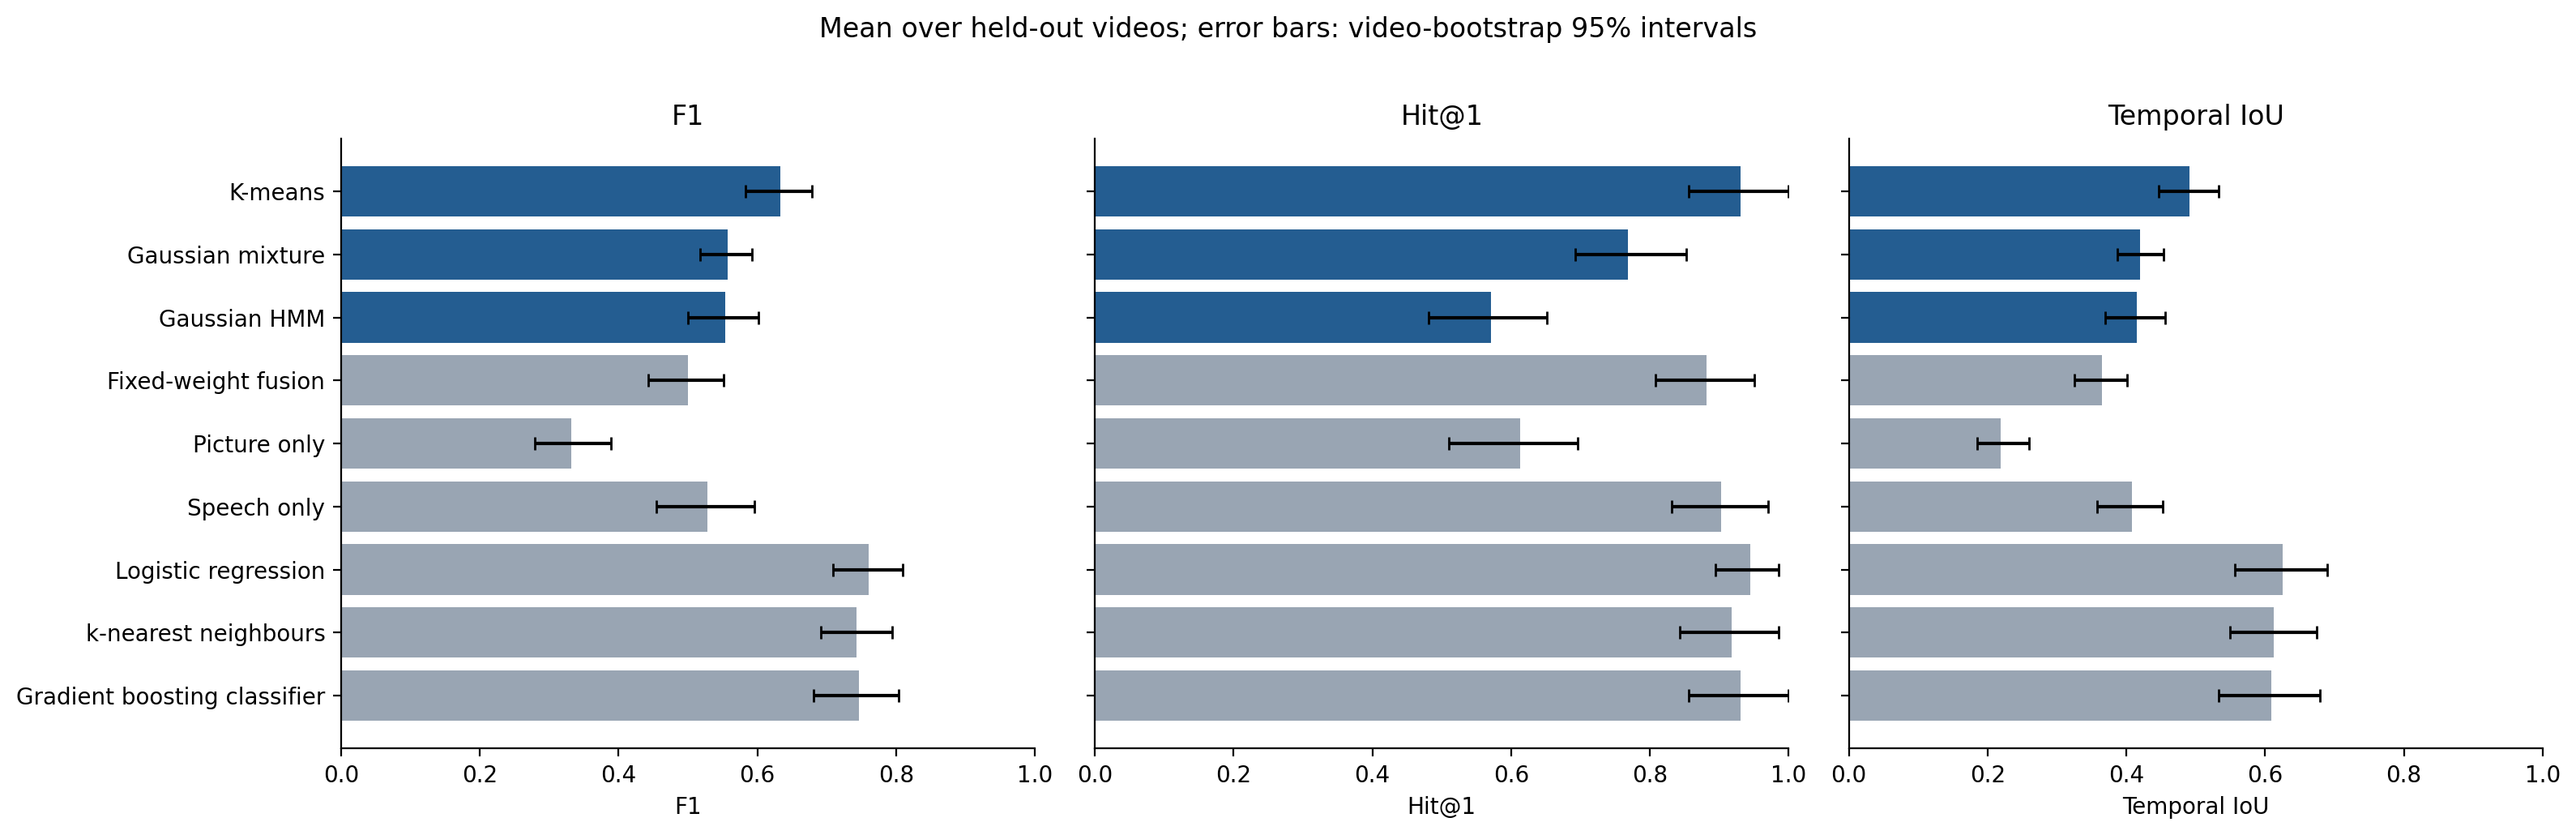

In [7]:
columns = ['method', 'precision', 'recall', 'f1', 'pr_auc', 'hit_at_1', 'hit_at_5', 'mrr', 'temporal_iou']
display(comparison[columns].round(3))
display(comparison[['method', 'f1_lo', 'f1_hi', 'hit_at_1_lo', 'hit_at_1_hi']].round(3))
display(Image(filename=str(OUT / 'figures' / '07_comparison.png')))

## 5. Result interpretation & presentation — 4 marks

The following statements are calculated from the measured results, not
expected improvements. An HMM can model persistent states while still
ranking relevant seconds poorly: maximum likelihood optimizes feature
density and transitions, not search relevance. Clusters can reflect speech
presence or background patterns rather than the answer interval.

- **K-means:** F1 0.633, Hit@1 0.930, temporal IoU 0.491.
- **Gaussian mixture:** F1 0.557, Hit@1 0.769, temporal IoU 0.419.
- **Gaussian HMM:** F1 0.554, Hit@1 0.571, temporal IoU 0.415.
- **Fixed-weight fusion:** F1 0.500, Hit@1 0.881, temporal IoU 0.365.
- **Logistic regression:** F1 0.761, Hit@1 0.944, temporal IoU 0.626.

HMM minus K-means F1: **-0.079**. This run does not support claiming that temporal modeling improves relevance performance.

,held_out,states,converged,iterations
0,a-remote-possibility,3,True,12
1,administrator-chats-astronauts,3,True,4
2,commercial-crew-milestone,3,True,12
3,cosmic-phenomenon,3,True,12
4,hubble-exoplanet,3,True,4
5,mars-mission-briefed,3,True,12
6,new-explorers-new-roadmap,3,True,12
7,smoke-and-fire,3,True,12
8,this-week-at-nasa,3,True,11


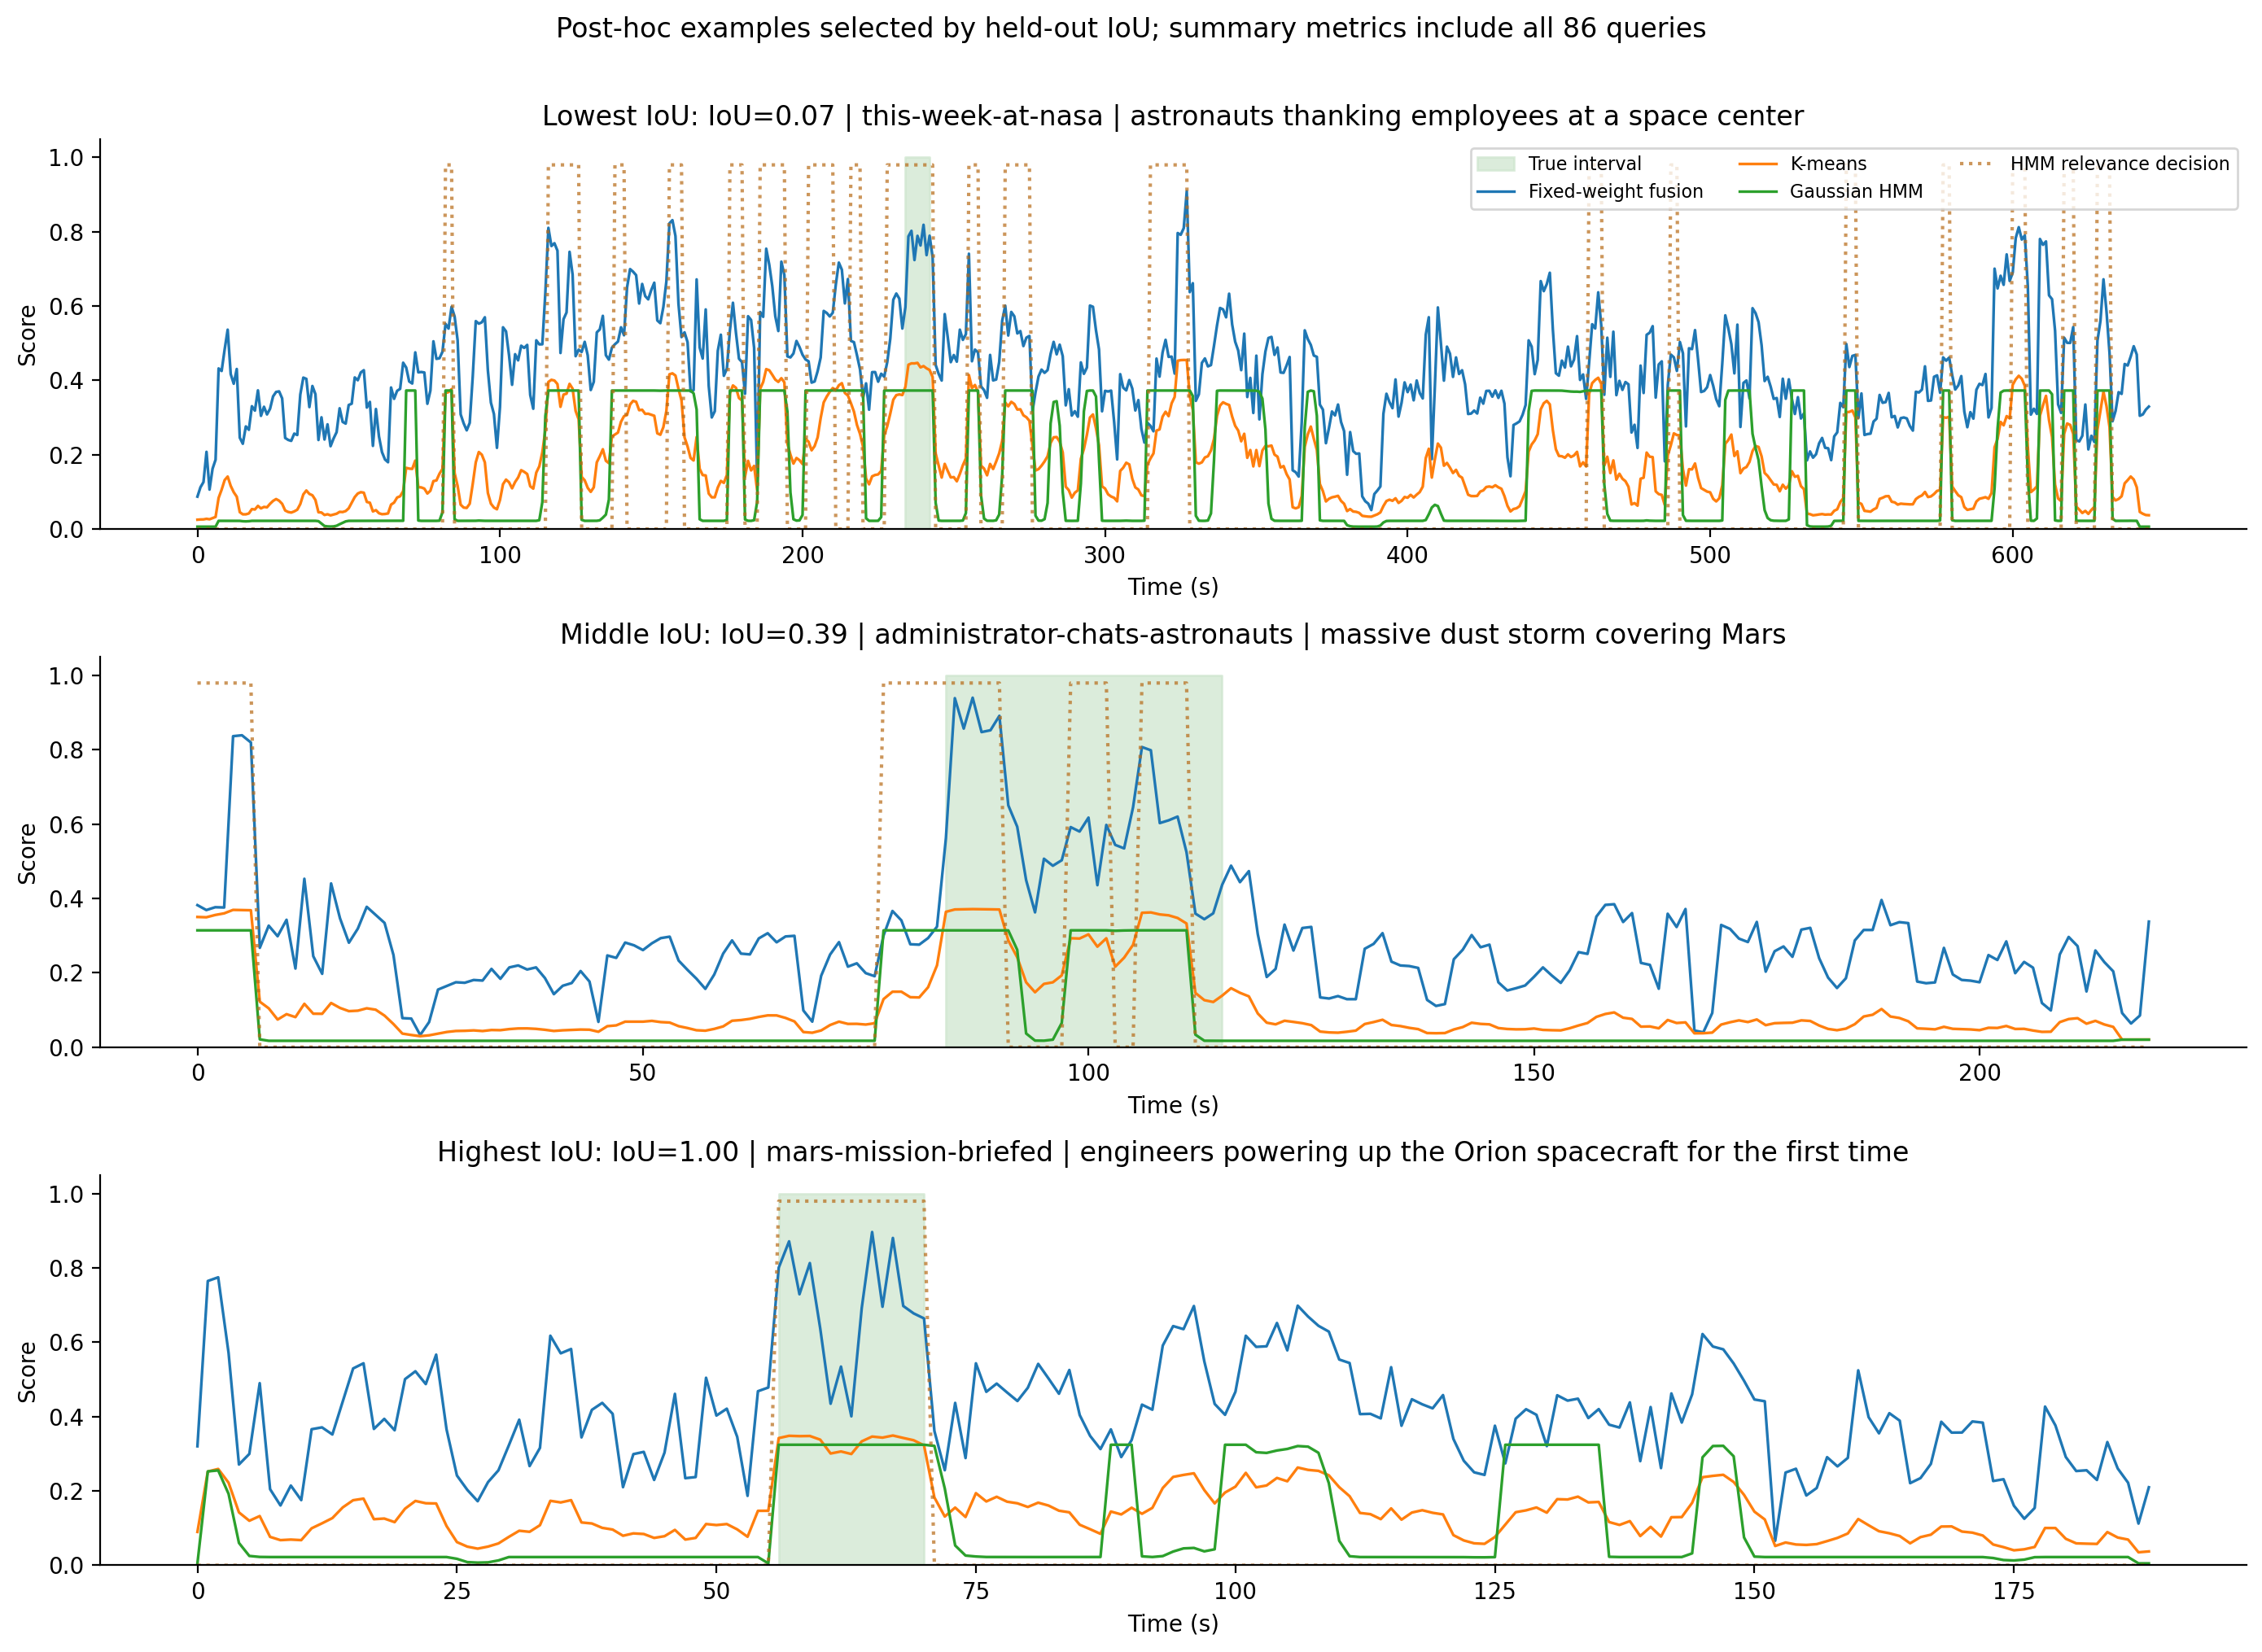

In [8]:
rows = comparison.set_index('method')
lines = []
for name in ['K-means', 'Gaussian mixture', 'Gaussian HMM', 'Fixed-weight fusion', 'Logistic regression']:
    row = rows.loc[name]
    lines.append(f"- **{name}:** F1 {row.f1:.3f}, Hit@1 {row.hit_at_1:.3f}, temporal IoU {row.temporal_iou:.3f}.")
hmm_delta = rows.loc['Gaussian HMM', 'f1'] - rows.loc['K-means', 'f1']
lines.append(f"\nHMM minus K-means F1: **{hmm_delta:+.3f}**. This run does not support claiming that temporal modeling improves relevance performance.")
display(Markdown('\n'.join(lines)))
display(pd.DataFrame([{'held_out': d['held_out'], 'states': d['models']['Gaussian HMM']['k'],
                       'converged': d['models']['Gaussian HMM']['converged'],
                       'iterations': d['models']['Gaussian HMM']['iterations']} for d in details]))
display(Image(filename=str(OUT / 'figures' / '08_example_timelines.png')))